In [1]:
import matplotlib.pyplot as plt

from src.core.config import EXPERIMENT_CONFIG
from src.core.utils import PoolingTypeEnum
from src.plots.data_loaders import (
    load_pair_edit_data,
    load_q1_projections,
    load_q1_results,
    load_q4_results,
)
from src.plots.plot_utils import save_figure
from src.plots.q1_plots import plot_projection_histogram
from src.plots.q4_plots import (
    plot_group_shares,
    plot_mean_projection_by_stratum,
)

supervised_corpus_name = 'real_aae'
layer = EXPERIMENT_CONFIG.primary_layer
dev_caption = 'Llama-3.2-3B, layer 14, Exploratory Development Split (3,782 Supervised Pairs)'

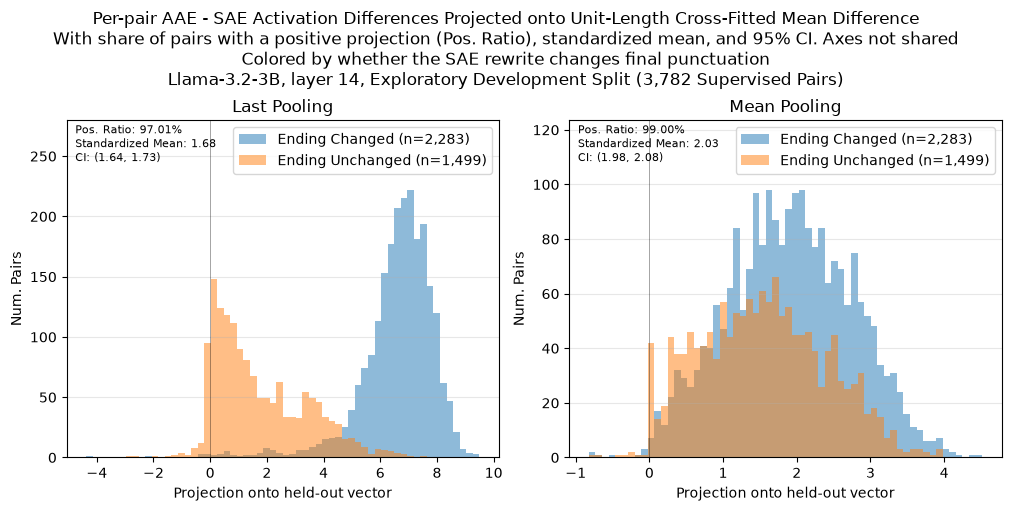

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), layout='constrained')
for ax, pooling_type in zip(axes, PoolingTypeEnum):
    plot_projection_histogram(
        load_q1_projections(supervised_corpus_name, layer, pooling_type),
        load_q1_results(supervised_corpus_name, layer, pooling_type),
        pair_edit_data=load_pair_edit_data(supervised_corpus_name),
        ax=ax,
    )
fig.suptitle(
    'Per-pair AAE - SAE Activation Differences Projected onto Unit-Length Cross-Fitted Mean Difference\n'
    'With share of pairs with a positive projection (Pos. Ratio), standardized mean, and 95% CI. Axes not shared\n'
    'Colored by whether the SAE rewrite changes final punctuation\n'
    + dev_caption
)
save_figure(fig, 'q1_projection_histogram')

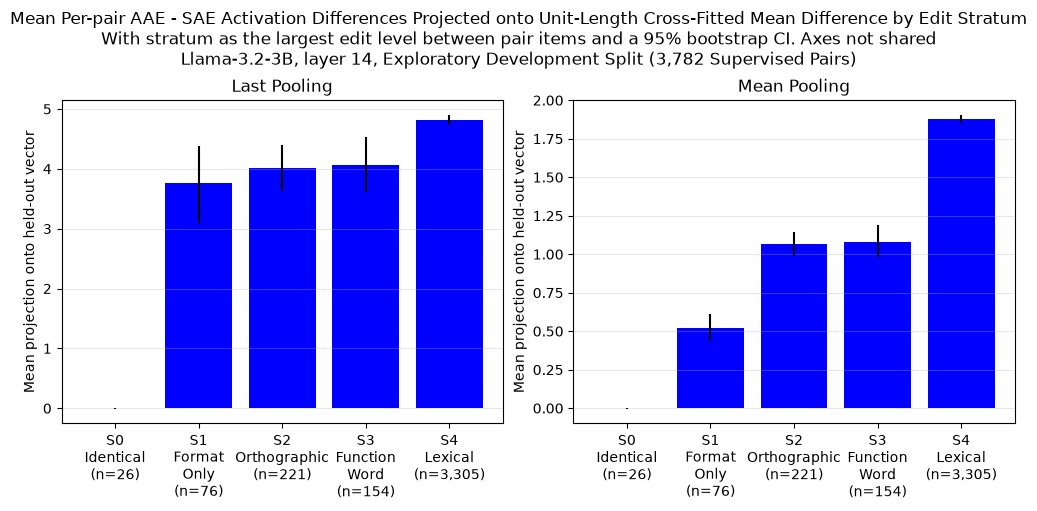

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), layout='constrained')
for ax, pooling_type in zip(axes, PoolingTypeEnum):
    plot_mean_projection_by_stratum(
        load_q4_results(supervised_corpus_name, layer, pooling_type),
        ax=ax,
    )
fig.suptitle(
    'Mean Per-pair AAE - SAE Activation Differences Projected onto Unit-Length Cross-Fitted Mean Difference by Edit Stratum\n'
    'With stratum as the largest edit level between pair items and a 95% bootstrap CI. Axes not shared\n'
    + dev_caption
)
save_figure(fig, 'q4_mean_projection_by_stratum')

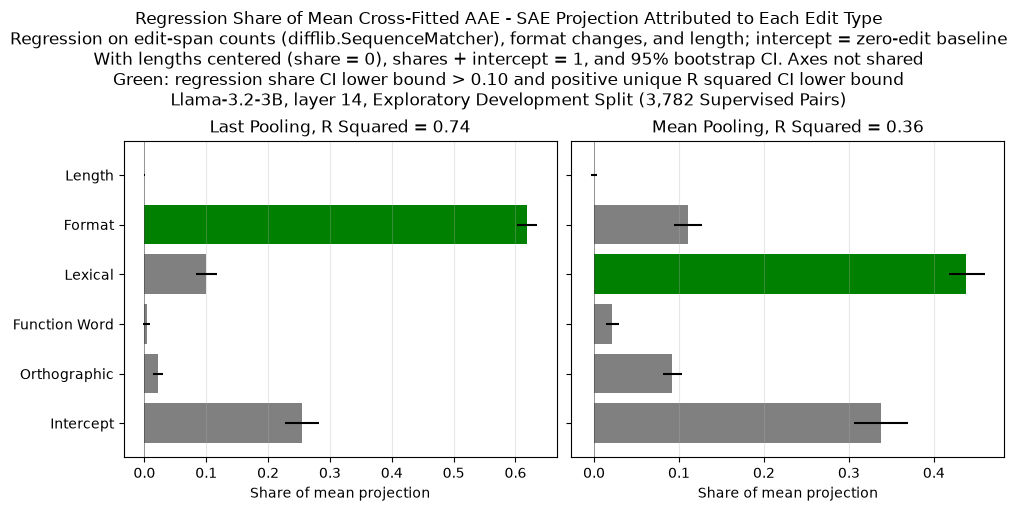

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True, layout='constrained')
for ax, pooling_type in zip(axes, PoolingTypeEnum):
    plot_group_shares(
        load_q4_results(supervised_corpus_name, layer, pooling_type),
        ax=ax,
    )
fig.suptitle(
    'Regression Share of Mean Cross-Fitted AAE - SAE Projection Attributed to Each Edit Type\n'
    'Regression on edit-span counts (difflib.SequenceMatcher), format changes, and length; intercept = zero-edit baseline\n'
    'With lengths centered (share = 0), shares + intercept = 1, and 95% bootstrap CI. Axes not shared\n'
    'Green: regression share CI lower bound > 0.10 and positive unique R squared CI lower bound\n'
    + dev_caption
)
save_figure(fig, 'q4_group_shares')